## Image Preprocessing - Grayscale + Canny Edge Detection

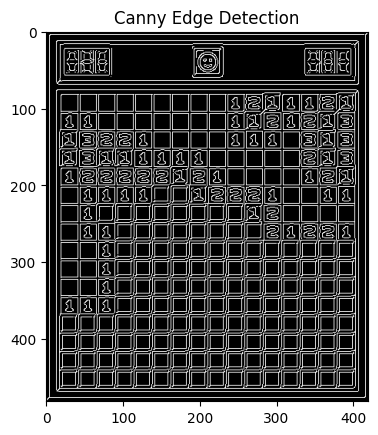

In [2]:
from skimage import io, color, feature
import matplotlib.pyplot as plt

#load image
img  = io.imread('Test Image 6.png')
#grayscale
gray = color.rgb2gray(img)              # Canny needs 2D grayscale
#canny edge detection
edges = feature.canny(gray, sigma=.9)    # returns a True/False edge map

plt.imshow(edges, cmap='gray')
plt.title("Canny Edge Detection")
plt.show()


## Data Extraction - Gridscan + Template Matching

## Logic Application - Minesweeper Logic

In [3]:
import collections
import itertools
import sys
import threading

CPU_COUNT = 1

class exception(Exception):
    pass

class UnsolveableException(exception):
    pass

Information = collections.namedtuple('Information', ('spaces', 'count'))

def choose(n, k):
    # by Andrew Dalke.
    if 0 <= k <= n:
        ntok = 1
        ktok = 1
        for t in range(1, min(k, n - k) + 1):
            ntok *= n
            ktok *= t
            n -= 1
        return ntok // ktok
    else:
        return 0

global_clusters_checked = set()

global_clusters_hits = itertools.count(0)
global_clusters_misses = itertools.count(0)
global_clusters_solves = itertools.count(0)

global_cluster_probabilities = {}

global_probabilities_hits = itertools.count(0)
global_probabilities_misses = itertools.count(0)

# threading utilities that should probably be elsewhere:

class Promise(object):
    def __init__(self, queue):
        self.lock = threading.Lock()
        self.finished = False
        self.value = None
        self.queue = queue
        self.lock.acquire()

    def set(self, value):
        self.value = value
        self.finished = True
        self.lock.release()

    def get(self):
        if not self.finished:
            while not self.lock.acquire(False):
                if not self.queue.run_one(False):
                    self.lock.acquire()
                    break
            self.lock.release()
        return self.value

class TaskQueue(object):
    def __init__(self, number_of_threads):
        self.tasks = []
        self.task_sem = threading.Semaphore(0)
        for i in range(number_of_threads):
            new_thread = threading.Thread(target=TaskQueue.run_forever, args=(self,))
            new_thread.daemon = True
            new_thread.start()
        self.number_of_threads = number_of_threads

    def run_task(self, task):
        f, args, kwargs, promise = task
        try:
            promise.set(f(*args, **kwargs))
        except BaseException as e:
            promise.set(e)

    def run_one(self, block=True):
        if self.task_sem.acquire(block):
            task = self.tasks.pop(0)
            self.run_task(task)
            return True
        else:
            return False

    def run_forever(self):
        while True:
            self.run_one()

    def add_task(self, f, args=(), kwargs={}, block=True):
        promise = Promise(self)
        self.tasks.append((f, args, kwargs, promise))
        self.task_sem.release()
        return promise

class DummyTaskQueue(TaskQueue):
    def add_task(self, f, args=(), kwargs={}, block=True):
        promise = Promise(self)
        promise.set(f(*args, **kwargs))
        return promise

if CPU_COUNT == 1:
    queue = DummyTaskQueue(0)
else:
    queue = TaskQueue(CPU_COUNT)

# actual minesweeper code

class Solver(object):
    def __init__(self, spaces):
        self.spaces = frozenset(spaces)
        self.solved_spaces = dict()
        self.information = set()
        self.informations_for_space = collections.defaultdict(set)
        self.spaces_to_add = []
        self.informations_to_add = []

    def add_information(self, information):
        if information.count < 0 or information.count > len(information.spaces):
            raise UnsolveableException()
        if information.count == 0:
            for space in information.spaces:
                self.add_known_value(space, 0)
        elif information.count == len(information.spaces):
            for space in information.spaces:
                self.add_known_value(space, 1)
        else:
            self.informations_to_add.append(information)

    def remove_information(self, information):
        self.information.remove(information)
        for space in information.spaces:
            self.informations_for_space[space].remove(information)

    def add_known_value(self, space, value):
        self.spaces_to_add.append((space, value))

    def copy(self):
        self.solve(np=False)
        result = Solver(self.spaces)
        result.solved_spaces = self.solved_spaces.copy()
        result.information = self.information.copy()
        for key, value in self.informations_for_space.items():
            result.informations_for_space[key] = value.copy()
        return result

    def get_clusters(self):
        informations_unassigned = set(self.information)
        result = set()

        while informations_unassigned:
            information = informations_unassigned.pop()
            cluster = set((information,))
            unchecked_spaces_in_cluster = set(information.spaces)

            while unchecked_spaces_in_cluster:
                space = unchecked_spaces_in_cluster.pop()
                for information in self.informations_for_space[space]:
                    if information in informations_unassigned:
                        informations_unassigned.remove(information)
                        cluster.add(information)
                        unchecked_spaces_in_cluster.update(information.spaces)

            result.add(frozenset(cluster))

        return result

    @staticmethod
    def get_cluster_probabilities(cluster):
        if len(cluster) == 1:
            cluster_possibilities = {}
            for information in cluster:
                break

            total = choose(len(information.spaces), information.count)
            p = total * information.count // len(information.spaces)

            for space in information.spaces:
                cluster_possibilities[space] = p

            return cluster_possibilities, total

        result = global_cluster_probabilities.get(cluster)
        if result is not None:
            next(global_probabilities_hits)
            return result

        next(global_probabilities_misses)

        spaces = set()
        for information in cluster:
            spaces.update(information.spaces)

        base_solver = Solver(spaces)

        for information in cluster:
            base_solver.add_information(information)

        information1 = information

        for information in cluster:
            if information is not information1 and not information.spaces.isdisjoint(information1.spaces):
                spaces = information.spaces.intersection(information1.spaces)
                max_mines = min(len(spaces), information.count, information1.count)
                break
        else:
            raise Exception("This shouldn't happen")

        total = 0
        possibilities = dict((space, 0) for space in base_solver.spaces)

        for i in range(max_mines+1):
            solver = base_solver.copy()
            try:
                solver.add_information(Information(spaces, i))
                solver_possibilities, solver_total = solver.get_probabilities()
            except UnsolveableException:
                continue
            total += solver_total
            for space in solver.spaces:
                if space in solver_possibilities:
                    possibilities[space] += solver_possibilities[space]
                elif solver.solved_spaces[space]:
                    possibilities[space] += solver_total

        global_cluster_probabilities[cluster] = possibilities, total

        return possibilities, total

    def get_probabilities(self):
        self.solve(np=False)
        clusters = self.get_clusters()
        result = {}
        denominator = 1

        for cluster in clusters:
            possibilities, total = Solver.get_cluster_probabilities(cluster)

            for space in result:
                result[space] *= total

            for space in possibilities:
                result[space] = possibilities[space] * denominator

            denominator *= total

        return result, denominator

    @staticmethod
    def get_cluster_possibility(cluster, rand):
        if len(cluster) == 1:
            result = {}

            for information in cluster:
                break

            count = information.count
            remaining_spaces = len(information.spaces)
            for space in information.spaces:
                if rand.randint(1, remaining_spaces) <= count:
                    count -= 1
                    result[space] = 1
                else:
                    result[space] = 0
                remaining_spaces -= 1

            return result

        spaces = set()
        for information in cluster:
            spaces.update(information.spaces)

        base_solver = Solver(spaces)

        for information in cluster:
            base_solver.add_information(information)

        information1 = information

        # try to choose the same set of spaces as get_cluster_probabilities,
        # so we can benefit from caching
        for information in cluster:
            if information is not information1 and not information.spaces.isdisjoint(information1.spaces):
                spaces = information.spaces.intersection(information1.spaces)
                max_mines = min(len(spaces), information.count, information1.count)
                break
        else:
            raise Exception("This shouldn't happen")

        total = 0
        possibilities = [0] * (max_mines+1)
        solvers = [None] * (max_mines+1)

        for i in range(max_mines+1):
            solver = base_solver.copy()
            try:
                solver.add_information(Information(spaces, i))
                _solver_possibilities, possibilities[i] = solver.get_probabilities()
                solvers[i] = solver
            except UnsolveableException:
                possibilities.append 
                continue
            total += possibilities[i]

        n = rand.randint(1, total)
        for i in range(max_mines+1):
            n -= possibilities[i]
            if n <= 0:
                break

        return solvers[i].get_possibility()

    def get_possibility(self, rand=None):
        self.solve(np=False)
        clusters = self.get_clusters()
        result = self.solved_spaces.copy()

        if rand is None:
            import random
            rand = random.Random()
            rand.seed()

        for cluster in clusters:
            result.update(Solver.get_cluster_possibility(cluster, rand))

        return result

    @staticmethod
    def solver_from_cluster(cluster):
        spaces = set()
        for information in cluster:
            spaces.update(information.spaces)

        result = Solver(spaces)
        for information in cluster:
            result.information.add(information)
            for space in information.spaces:
                result.informations_for_space[space].add(information)

        return result

    def check_state(solver, states_to_validate):
        try:
            solver.solve(np=False)
        except UnsolveableException:
            return False

        if len(solver.solved_spaces) != len(solver.spaces):
            clusters = solver.get_clusters()

            states_validated = set(solver.solved_spaces.items())

            for cluster in clusters:
                cluster_solver = Solver.solver_from_cluster(cluster)

                if len(cluster) <= 2:
                    # solver.solve can handle this trivially
                    states_validated.update((space, 0) for space in cluster_solver.spaces)
                    states_validated.update((space, 1) for space in cluster_solver.spaces)
                    continue

                # Find a space in the most informations
                max_space = None
                max_information = 0
                max_information_size = 0
                for space in cluster_solver.spaces:
                    if len(cluster_solver.informations_for_space[space]) > 1:
                        i = iter(cluster_solver.informations_for_space[space])
                        information1 = next(i)
                        information2 = next(i)
                        spaces = information1.spaces.intersection(information2.spaces)
                        max_mines = min(len(spaces), information1.count, information2.count)
                        break
                else:
                    assert False

                first_attempt = 0
                for space in spaces:
                    if (space, 0) not in states_to_validate and (space, 1) in states_to_validate:
                        first_attempt += 1
                if first_attempt > max_mines:
                    first_attempt = max_mines

                for i in range(max_mines+1):
                    if i == 0:
                        i = first_attempt
                    elif i == first_attempt:
                        i = 0
                    check_solver = cluster_solver.copy()
                    try:
                        check_solver.add_information(Information(spaces, i))
                    except UnsolveableException:
                        continue
                    res = check_solver.check_state(states_to_validate)
                    if res:
                        break
                else:
                    return False

                states_validated.update(res)

            return states_validated
        else:
            return solver.solved_spaces.items()

    def solve_cluster(self, cluster):
        base_solver = Solver.solver_from_cluster(cluster)

        spaces = base_solver.spaces

        states_to_validate = set()
        states_to_validate.update((x, 0) for x in spaces)
        states_to_validate.update((x, 1) for x in spaces)

        while states_to_validate:
            space, value = states_to_validate.pop()

            solver = base_solver.copy()

            solver.add_known_value(space, value)

            res = solver.check_state(states_to_validate)

            if res:
                states_validated = res
                states_to_validate.difference_update(states_validated)
            else:
                self.add_known_value(space, value ^ 1)
                next(global_clusters_solves)
                return True

        global_clusters_checked.add(cluster)
        next(global_clusters_misses)
        return False

    def solve_np(self):
        clusters = self.get_clusters()

        promises = []

        res = False

        for cluster in clusters:
            if len(cluster) <= 2:
                continue

            if cluster in global_clusters_checked:
                next(global_clusters_hits)
                continue

            promises.append(queue.add_task(Solver.solve_cluster, args=(self, cluster)))

        for promise in promises:
            if promise.get():
                res = True

        return res

    def solve(self, np=True):
        while True:
            if self.spaces_to_add:
                space, value = self.spaces_to_add.pop()

                if space in self.solved_spaces:
                    if self.solved_spaces[space] != value:
                        raise UnsolveableException
                    continue
                for information in list(self.informations_for_space.get(space, ())):
                    new_information = Information(
                        information.spaces.difference((space,)),
                        information.count - value)
                    self.remove_information(information)
                    self.add_information(new_information)
                self.solved_spaces[space] = value
            elif self.informations_to_add:
                information = self.informations_to_add.pop()

                modified = False
                for space in information.spaces:
                    if space in self.solved_spaces:
                        information = Information(
                            information.spaces.difference((space,)),
                            information.count - self.solved_spaces[space])
                        modified = True
                if modified:
                    self.add_information(information)
                    continue

                if information in self.information:
                    continue

                intersecting_informations = set()
                for space in information.spaces:
                    intersecting_informations.update(self.informations_for_space.get(space, ()))

                for other_information in intersecting_informations:
                    if information.spaces.issubset(other_information.spaces):
                        new_information = Information(
                            other_information.spaces.difference(information.spaces),
                            other_information.count - information.count)
                        self.remove_information(other_information)
                        self.add_information(new_information)

                    elif other_information.spaces.issubset(information.spaces):
                        new_information = Information(
                            information.spaces.difference(other_information.spaces),
                            information.count - other_information.count)
                        self.add_information(new_information)
                        break

                    elif other_information.count - len(other_information.spaces.difference(information.spaces)) >= information.count:
                        for space in other_information.spaces.difference(information.spaces):
                            self.add_known_value(space, 1)
                        for space in information.spaces.difference(other_information.spaces):
                            self.add_known_value(space, 0)

                    elif information.count - len(information.spaces.difference(other_information.spaces)) >= other_information.count:
                        for space in other_information.spaces.difference(information.spaces):
                            self.add_known_value(space, 0)
                        for space in information.spaces.difference(other_information.spaces):
                            self.add_known_value(space, 1)
                else:
                    self.information.add(information)
                    for space in information.spaces:
                        self.informations_for_space[space].add(information)

            elif not np or not self.solve_np():
                break


def solve_board(board, total_mines=None):
    
    if not board or not board[0]:
        raise ValueError("Board cannot be empty")

    m = len(board)
    n = len(board[0])

    if any(len(row) != n for row in board):
        raise ValueError("Board must be rectangular")

    spaces = {
        (x, y)
        for y in range(m)
        for x in range(n)
    }

    solver = Solver(spaces)

    for y in range(m):
        for x in range(n):
            value = board[y][x]
            space = (x, y)

            if value == -1:
                continue

            if value == -2:
                solver.add_known_value(space, 1)
                continue

            if not isinstance(value, int) or not 0 <= value <= 8:
                raise ValueError(
                    f"Invalid cell value {value!r} at {(x, y)}"
                )

            solver.add_known_value(space, 0)

            neighbors = frozenset(
                (nx, ny)
                for nx in range(max(0, x - 1), min(n, x + 2))
                for ny in range(max(0, y - 1), min(m, y + 2))
                if (nx, ny) != space
            )

            solver.add_information(
                Information(neighbors, value)
            )

    if total_mines is not None:
        solver.add_information(
            Information(frozenset(spaces), total_mines)
        )

    solver.solve()
    return solver


def picma_main(width, height):
    spaces = set((x,y) for x in range(width) for y in range(height))

    solver = Solver(spaces)

    for y in range(height):
        for x in range(width):
            char = sys.stdin.read(1)
            while char not in '-0123456789':
                char = sys.stdin.read(1)

            if char.isdigit():
                info_count = int(char)
                info_spaces = frozenset((xs,ys) for xs in range(x-1, x+2) for ys in range(y-1, y+2)).intersection(spaces)
                solver.add_information(Information(info_spaces, info_count))

    try:
        solver.solve()
    except UnsolveableException:
        print ("This configuration has no solutions.")
        return

    for y in range(height):
        for x in range(width):
            sys.stdout.write(str(solver.solved_spaces.get((x, y), '-')))
        sys.stdout.write('\n')

    for i in solver.information:
        print (i)

def mines_main(width, height, total):
    spaces = set((x,y) for x in range(width) for y in range(height))

    solver = Solver(spaces)

    for y in range(height):
        for x in range(width):
            char = sys.stdin.read(1)
            while char not in '-0123456789m':
                char = sys.stdin.read(1)

            if char.isdigit():
                info_count = int(char)
                info_spaces = frozenset((xs,ys) for xs in range(x-1, x+2) for ys in range(y-1, y+2)).intersection(spaces)
                solver.add_information(Information(info_spaces, info_count))
                solver.add_known_value((x, y), 0)
            elif char == 'm':
                solver.add_known_value((x, y), 1)

    solver.add_information(Information(frozenset(spaces), total))

    try:
        solver.solve()
    except UnsolveableException:
        print ("This configuration has no solutions.")
        return

    sys.stdout.write('\n')

    for y in range(height):
        for x in range(width):
            sys.stdout.write(str(solver.solved_spaces.get((x, y), '-')))
        sys.stdout.write('\n')

    for i in solver.information:
        print (i)

    probabilities, total = solver.get_probabilities()

    probabilities = [(probability, space) for (space, probability) in probabilities.items()]

    probabilities.sort()

    print ('total possible arrangements:', total)

    total = float(total)

    for probability, space in probabilities:
        print (space, probability / total)

class MineMap(object):
    def __init__(self, spaces):
        self.spaces = frozenset(spaces)

    def __getitem__(self, key):
        raise NotImplementedError()

    def __setitem__(self, key, value):
        raise NotImplementedError()

    def get_bordering_spaces(self, space):
        raise NotImplementedError()

    def randomize_p(self, random, p=0.5):
        for space in self.spaces:
            self[space] = 1 if random.random() < p else 0

    def randomize_count(self, random, count):
        mines_remaining = count
        spaces_remaining = len(self.spaces)
        for space in self.spaces:
            value = 1 if random.randint(1, spaces_remaining) <= mines_remaining else 0
            self[space] = value
            mines_remaining -= value
            spaces_remaining -= 1

class RectMap(MineMap):
    def __init__(self, width, height):
        spaces = set()
        for x in range(width):
            for y in range(height):
                spaces.add((x, y))
        MineMap.__init__(self, spaces)

        self.width = width
        self.height = height

        self.values = [0] * width * height

    def __getitem__(self, key):
        x, y = key
        return self.values[x + y * self.width]

    def __setitem__(self, key, value):
        x, y = key
        self.values[x + y * self.width] = value

    def get_bordering_spaces(self, space):
        result = set()
        x, y = space
        for xb in range(max(x-1, 0), min(x+2, self.width)):
            for yb in range(max(y-1, 0), min(y+2, self.height)):
                result.add((xb, yb))
        return result

class PicmaPuzzle(object):
    def __init__(self, minemap):
        self.minemap = minemap
        self.known_spaces = dict()

    def create_solver(self):
        result = Solver(self.minemap.spaces)
        for key, value in self.known_spaces.items():
            result.add_information(Information(frozenset(self.minemap.get_bordering_spaces(key)), value))
        return result

    def make_solveable(self, random):
        solver = self.create_solver()
        solver.solve()

        spaces_left_to_add = set(self.minemap.spaces)
        spaces_left_to_add.difference_update(self.known_spaces.keys())
        spaces_left_to_add = list(spaces_left_to_add)
        random.shuffle(spaces_left_to_add)

        while len(self.minemap.spaces) != len(solver.solved_spaces):
            if not spaces_left_to_add:
                raise ValueError("Unsolveable configuration")
            space = spaces_left_to_add.pop()
            bordering_spaces = frozenset(self.minemap.get_bordering_spaces(space))

            value = sum(self.minemap[s] for s in bordering_spaces)

            new_solver = solver.copy()
            new_solver.add_information(Information(bordering_spaces, value))
            new_solver.solve()

            if new_solver.solved_spaces != solver.solved_spaces or \
                new_solver.information != solver.information:
                self.known_spaces[space] = value
                solver = new_solver

    def trim(self):
        for space, value in self.known_spaces.items():
            del self.known_spaces[space]
            solver = self.create_solver()
            solver.solve()
            if len(self.minemap.spaces) != len(solver.solved_spaces):
                self.known_spaces[space] = value


def picmagen(rectmap, random):
    puzzle = PicmaPuzzle(rectmap)
    try:
        puzzle.make_solveable(random)
    except ValueError:
        print ("unsolveable configuration:")
        for y in range(rectmap.height):
            for x in range(rectmap.width):
                sys.stdout.write(str(rectmap[x, y]))
            sys.stdout.write('\n')
    else:
        puzzle.trim()

    for y in range(rectmap.height):
        for x in range(rectmap.width):
            sys.stdout.write(str(puzzle.known_spaces.get((x, y), '-')))
        sys.stdout.write('\n')

    print ("hits: ", next(global_clusters_hits))
    print ("misses: ", next(global_clusters_misses))
    print ("solves: ", next(global_clusters_solves))

def picmagen_main(width, height):
    import random
    random = random.SystemRandom()

    rectmap = RectMap(width, height)
    rectmap.randomize_p(random)

    picmagen(rectmap, random)

def picmapregen_main(width, height):
    import random
    random = random.SystemRandom()

    rectmap = RectMap(width, height)

    for y in range(height):
        for x in range(width):
            char = sys.stdin.read(1)
            while char not in '01':
                char = sys.stdin.read(1)

            rectmap[x, y] = int(char)

    picmagen(rectmap, random)

if __name__ == '__main__':
    if sys.argv[1] == 'picma':
        picma_main(int(sys.argv[2]), int(sys.argv[3]))
    elif sys.argv[1] == 'mines':
        mines_main(int(sys.argv[2]), int(sys.argv[3]), int(sys.argv[4]))
    elif sys.argv[1] == 'picmagen':
        picmagen_main(int(sys.argv[2]), int(sys.argv[3]))
    elif sys.argv[1] == 'picmapregen':
        picmapregen_main(int(sys.argv[2]), int(sys.argv[3]))

In [25]:
from termcolor import colored

# 0-8 represents the number on the tile; how many mines are adjacent
# -1 represents unchecked tiles
# -2 represents a mine
board = [
    [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 2, -2, 1, 1, 2, -2],
    [1, 1, 0, 0, 0, 0, 0, 0, 0, 1, -2, 2, 1, 2, -2, 3],
    [-2, 3, 2, 2, 1, 0, 0, 0, 0, 1, 1, 1, 0, 3, -2, 3],
    [-2, 3, -2, -2, 1, 1, 1, 1, 0, 0, 0, 0, 0, 2, -2, 3],
    [1, 2, 2, 2, 2, 2, -2, 2, 1, 0, 0, 0, 0, 1, 2, -2],
    [0, 1, 1, 1, 1, -1, -1, -2, 2, 2, 2, 1, 0, 0, 1, 1],
    [0, 1, -1, -1, -1, -1, -1, -1, -1, -1, -2, 2, 0, 0, 0, 0],
    [0, 1, 1, -1, -1, -1, -1, -1, -1, -1, -1, 2, 1, 2, 2, 1],
    [0, 0, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1],
    [0, 0, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1],
    [0, 0, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1],
    [1, 1, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1],
    [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1],
    [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1],
    [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1],
    [-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
]

solver = solve_board(board,total_mines =40)


for y in range(len(board)):
    print([
        solver.solved_spaces.get((x, y), -1)
        for x in range(len(board[0]))
    ])

print('')
print('0 = Checked | -1 = Unchecked | 1 = Mine')


[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 1, 0]
[1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0]
[1, 0, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0]
[0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1]
[0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 1, 0, 0, 0, -1, 0, 0, 1, 1, 0, 0, 0, 0, 0]
[0, 0, 0, 0, -1, -1, -1, -1, -1, -1, 1, 0, 0, 0, 0, 0]
[0, 0, 0, 0, -1, -1, -1, -1, -1, -1, 0, 0, 0, 1, 1, 0]
[0, 0, 0, 1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
[0, 0, 0, 0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
[0, 0, 0, 0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
[-1, -1, 0, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
[-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
[-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]
[-1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1]

0 = Checked | -1 = Unchecked | 1 = Mine
